# STADIOEquities: First-Deposit Activation
## SS3 Part B

This notebook applies the Gradient Boosting method selected in SS2
to the supplied STADIOEquities client dataset to investigate
first-deposit activation.

# 1. Dataset Loading

The six client-provided CSV files contain customer acquisition, onboarding, app/web behaviour, funding, marketing engagement and customer support data.

In [2]:
import pandas as pd

customer_acquisition = pd.read_csv("data/raw/table1_customer_acquisition.csv")
kyc_onboarding = pd.read_csv("data/raw/table2_kyc_onboarding.csv")
app_web_behaviour = pd.read_csv("data/raw/table3_app_web_behaviour.csv")
funding_deposits = pd.read_csv("data/raw/table4_funding_deposits.csv")
marketing_engagement = pd.read_csv("data/raw/table5_marketing_engagement.csv")
customer_support = pd.read_csv("data/raw/table6_customer_support.csv")

print("All six datasets loaded successfully.")

All six datasets loaded successfully.


In [3]:
datasets = {
    "Customer acquisition": customer_acquisition,
    "KYC onboarding": kyc_onboarding,
    "App/web behaviour": app_web_behaviour,
    "Funding/deposits": funding_deposits,
    "Marketing engagement": marketing_engagement,
    "Customer support": customer_support
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Customer acquisition: 2,418 rows, 9 columns
KYC onboarding: 2,411 rows, 7 columns
App/web behaviour: 14,196 rows, 9 columns
Funding/deposits: 2,411 rows, 8 columns
Marketing engagement: 13,223 rows, 9 columns
Customer support: 1,387 rows, 8 columns


**Data format justification**

The client supplied the six datasets in CS) format. CSV is suitable for this analysis because it stores tabular data in a simple format that can be loaded directly into pandas DataFrames using `read_csv()`.

The six tables are kept separate during loading because they contain different types of records and have different levels of detail. They will be cleaned and prepared before being joined using `customer_id` during preprocessing.

## 2. Dataset Preprocessing

### Objective

The six datasets contain customer information recorded at different levels of detail. Before training the Gradient Boosting model, the data must be checked for quality, cleaned where necessary, and prepared for analysis.

The preprocessing stage will:

1. Check for missing values and duplicate records.
2. Check data types, dates and inconsistent category values.
3. Examine the timing of first successful deposits.
4. Prepare the data to measure customer behaviour during the first 7 days after registration and determine whether first deposit activation occurs within 30 days.
5. Prepare the cleaned datasets for combination at customer level, while preventing target leakage.

In [4]:
# Check the quality of each dataset

datasets = {
    "Customer acquisition": customer_acquisition,
    "KYC onboarding": kyc_onboarding,
    "App/web behaviour": app_web_behaviour,
    "Funding/deposits": funding_deposits,
    "Marketing engagement": marketing_engagement,
    "Customer support": customer_support
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows and columns:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isnull().sum().sum())



--- Customer acquisition ---
Rows and columns: (2418, 9)
Duplicate rows: 7
Missing values: 324

--- KYC onboarding ---
Rows and columns: (2411, 7)
Duplicate rows: 0
Missing values: 2775

--- App/web behaviour ---
Rows and columns: (14196, 9)
Duplicate rows: 0
Missing values: 128

--- Funding/deposits ---
Rows and columns: (2411, 8)
Duplicate rows: 0
Missing values: 8237

--- Marketing engagement ---
Rows and columns: (13223, 9)
Duplicate rows: 0
Missing values: 0

--- Customer support ---
Rows and columns: (1387, 8)
Duplicate rows: 0
Missing values: 348


In [5]:
# Identify the columns containing missing values

for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print(f"\n--- {name} ---")
        print(missing.sort_values(ascending=False))


--- Customer acquisition ---
campaign_id    311
age             13
dtype: int64

--- KYC onboarding ---
failure_reason                1713
kyc_completion_date           1030
time_spent_on_step_minutes      32
dtype: int64

--- App/web behaviour ---
session_duration_seconds    128
dtype: int64

--- Funding/deposits ---
failure_reason                2204
first_deposit_date            1337
first_deposit_amount_zar      1337
time_to_first_deposit_days    1337
transaction_status            1011
deposit_method                1011
dtype: int64

--- Customer support ---
resolution_time_hours    321
response_time_hours       27
dtype: int64


In [6]:
# Checking repeated customer IDs in each dataset

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Rows:", len(df))
    print("Unique customer IDs:", df["customer_id"].nunique())
    print("Missing customer IDs:", df["customer_id"].isnull().sum())
    print("Rows with repeated customer IDs:",
          df["customer_id"].duplicated().sum())


--- Customer acquisition ---
Rows: 2418
Unique customer IDs: 2411
Missing customer IDs: 0
Rows with repeated customer IDs: 7

--- KYC onboarding ---
Rows: 2411
Unique customer IDs: 2411
Missing customer IDs: 0
Rows with repeated customer IDs: 0

--- App/web behaviour ---
Rows: 14196
Unique customer IDs: 2411
Missing customer IDs: 0
Rows with repeated customer IDs: 11785

--- Funding/deposits ---
Rows: 2411
Unique customer IDs: 2411
Missing customer IDs: 0
Rows with repeated customer IDs: 0

--- Marketing engagement ---
Rows: 13223
Unique customer IDs: 2411
Missing customer IDs: 0
Rows with repeated customer IDs: 10812

--- Customer support ---
Rows: 1387
Unique customer IDs: 927
Missing customer IDs: 0
Rows with repeated customer IDs: 460


In [7]:
# Displaying exact duplicate rows in customer acquisition

customer_acquisition[
    customer_acquisition.duplicated(keep=False)
].sort_values("customer_id")

,customer_id,registration_date,age,region_province,investment_goal,risk_appetite,acquisition_channel,campaign_id,acquisition_cost_zar
137,STUE100962,2025-04-02 12:16:26,40.0,Mpumalanga,Education fund,Moderate,Social Media,CAMP2025_04,178.37
2414,STUE100962,2025-04-02 12:16:26,40.0,Mpumalanga,Education fund,Moderate,Social Media,CAMP2025_04,178.37
152,STUE101064,2024-07-19 12:10:53,35.0,Gauteng,Retirement,Conservative,Affiliate,CAMP2024_07,64.72
2416,STUE101064,2024-07-19 12:10:53,35.0,Gauteng,Retirement,Conservative,Affiliate,CAMP2024_07,64.72
250,STUE101753,2024-09-02 16:36:39,42.0,KwaZulu-Natal,Long-term growth,Moderate,Google Search,CAMP2024_09,551.08
2417,STUE101753,2024-09-02 16:36:39,42.0,KwaZulu-Natal,Long-term growth,Moderate,Google Search,CAMP2024_09,551.08
515,STUE103608,2025-06-20 15:32:18,34.0,KwaZulu-Natal,Wealth preservation,Aggressive,Google Search,CAMP2025_06,160.93
2415,STUE103608,2025-06-20 15:32:18,34.0,KwaZulu-Natal,Wealth preservation,Aggressive,Google Search,CAMP2025_06,160.93
915,STUE106411,2025-03-13 20:28:42,18.0,Gauteng,Short-term gains,Balanced,Google Search,CAMP2025_03,46.13
2411,STUE106411,2025-03-13 20:28:42,18.0,Gauteng,Short-term gains,Balanced,Google Search,CAMP2025_03,46.13


**Removing exact duplicate records**

The customer acquisition table contains seven extra rows that are exact duplicates of existing records. Since each duplicate has the same customer ID and identical values across all columns, retaining both copies would give those customers unnecessary extra weight in the analysis.

The duplicates are removed from the working DataFrame only. The original client-provided CSV file remains unchanged.

In [8]:
# Removing exact duplicate rows from customer acquisition

customer_acquisition = customer_acquisition.drop_duplicates()

print("Rows after removing duplicates:", len(customer_acquisition))
print("Unique customer IDs:", customer_acquisition["customer_id"].nunique())
print("Remaining duplicate rows:", customer_acquisition.duplicated().sum())

Rows after removing duplicates: 2411
Unique customer IDs: 2411
Remaining duplicate rows: 0


**Investigating first deposit outcomes**

The funding and deposits table is the primary source for determining whether a customer successfully activated. Before creating the activation target, we will inspect transaction statuses, missing deposit dates, and the recorded time to first deposit.

This is important because a failed deposit attempt does not count as activation. The intended outcome is a successful first deposit within 30 days of registration, while predictors will use only information available during the first seven days.

In [9]:
print("Transaction status counts:")
print(funding_deposits["transaction_status"].value_counts(dropna=False))

print("\nDeposit method counts:")
print(funding_deposits["deposit_method"].value_counts(dropna=False))

print("\nFirst-deposit date availability:")
print(funding_deposits["first_deposit_date"].notna().value_counts())

print("\nTime to first deposit (days):")
print(funding_deposits["time_to_first_deposit_days"].describe())

print("\nTransaction status and first-deposit date:")
print(pd.crosstab(
    funding_deposits["transaction_status"],
    funding_deposits["first_deposit_date"].isna(),
    dropna=False
))

Transaction status counts:
transaction_status
Successful      1061
NaN             1011
Failed           205
Pending           81
Reversed          37
SUCCESSFUL         6
 Successful        5
successful         2
 Pending           1
 Failed            1
failed             1
Name: count, dtype: int64

Deposit method counts:
deposit_method
NaN              1011
Instant EFT       389
EFT               320
Debit Card        269
Credit Card       162
Capitec Pay       117
PayShap            68
Ozow               56
 Instant EFT        4
Instant  EFT        4
debit card          3
eft                 2
ozow                1
CREDIT CARD         1
credit card         1
INSTANT EFT         1
capitec pay         1
DEBIT CARD          1
Name: count, dtype: int64

First-deposit date availability:
first_deposit_date
False    1337
True     1074
Name: count, dtype: int64

Time to first deposit (days):
count    1074.000000
mean        4.429330
std         4.061662
min         0.000000
25%         0.

**Investigating inconsistent deposit records**

The funding table contains inconsistent transaction status labels and some records where the transaction status and first deposit date do not appear to agree. Status values will be standardised after these cases have been inspected.

A successful first deposit should have a valid deposit date, and its timing should be consistent with the customer's registration date. Investigating these inconsistencies helps ensure that the activation target is based on reliable evidence rather than assumptions.

In [11]:
# Standardising status labels temporarily for inspection

status_check = (
    funding_deposits["transaction_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

date_missing = funding_deposits["first_deposit_date"].isna()

print("Status counts after trimming spaces and ignoring case:")
print(status_check.value_counts(dropna=False))

print("\nSuccessful status but missing deposit date:")
print(funding_deposits[
    status_check.eq("successful") & date_missing
])

print("\nDeposit date present but status is not successful:")
print(funding_deposits[
    funding_deposits["first_deposit_date"].notna()
    & ~status_check.eq("successful")
])

Status counts after trimming spaces and ignoring case:
transaction_status
successful    1074
<NA>          1011
failed         207
pending         82
reversed        37
Name: count, dtype: Int64

Successful status but missing deposit date:
Empty DataFrame
Columns: [customer_id, first_deposit_date, first_deposit_amount_zar, deposit_attempt, transaction_status, failure_reason, deposit_method, time_to_first_deposit_days]
Index: []

Deposit date present but status is not successful:
Empty DataFrame
Columns: [customer_id, first_deposit_date, first_deposit_amount_zar, deposit_attempt, transaction_status, failure_reason, deposit_method, time_to_first_deposit_days]
Index: []


In [12]:
# Comparing the recorded deposit timing with the registration and deposit dates

acquisition_dates = customer_acquisition[
    ["customer_id", "registration_date"]
].copy()

acquisition_dates["registration_date"] = pd.to_datetime(
    acquisition_dates["registration_date"], errors="coerce"
)

funding_dates = funding_deposits[
    ["customer_id", "first_deposit_date", "time_to_first_deposit_days"]
].copy()

funding_dates["first_deposit_date"] = pd.to_datetime(
    funding_dates["first_deposit_date"], errors="coerce"
)

date_check = acquisition_dates.merge(
    funding_dates,
    on="customer_id",
    how="inner"
)

date_check["calculated_days"] = (
    date_check["first_deposit_date"]
    - date_check["registration_date"]
).dt.total_seconds() / 86400

print("Records with missing or invalid dates:")
print(date_check[
    date_check["registration_date"].isna()
    | date_check["first_deposit_date"].isna()
].shape[0])

print("\nRecords with a deposit before registration:")
print(date_check[date_check["calculated_days"] < 0][
    ["customer_id", "registration_date", "first_deposit_date",
     "calculated_days", "time_to_first_deposit_days"]
])

print("\nComparison of calculated and recorded deposit timing:")
print(date_check[
    date_check["first_deposit_date"].notna()
    & date_check["registration_date"].notna()
][["calculated_days", "time_to_first_deposit_days"]].describe())

print("\nSample of calculated versus recorded timing:")
print(date_check[
    date_check["first_deposit_date"].notna()
    & date_check["registration_date"].notna()
][["customer_id", "registration_date", "first_deposit_date",
   "calculated_days", "time_to_first_deposit_days"]].head(10))


Records with missing or invalid dates:
1345

Records with a deposit before registration:
Empty DataFrame
Columns: [customer_id, registration_date, first_deposit_date, calculated_days, time_to_first_deposit_days]
Index: []

Comparison of calculated and recorded deposit timing:
       calculated_days  time_to_first_deposit_days
count      1066.000000                 1066.000000
mean          4.880605                    4.418856
std           4.063724                    4.038790
min           0.000081                    0.000000
25%           0.948238                    0.500000
50%           4.306314                    3.900000
75%           7.695124                    7.175000
max          20.321377                   20.000000

Sample of calculated versus recorded timing:
   customer_id   registration_date  first_deposit_date  calculated_days  \
0   STUE100000 2025-02-12 10:12:50 2025-02-16 14:27:51         4.177095   
1   STUE100011 2024-04-28 16:21:51 2024-05-08 23:30:48        10.297

**Establishing the activation window**

This analysis uses the first seven days after registration as the observation period and the first 30 days as the activation outcome window.

Customers who make their first successful deposit within seven days are excluded from the Day 7 prediction population because they have already activated. For the remaining customers, the target indicates whether a first successful deposit occurs after Day 7 and within 30 days of registration.

Elapsed time will be calculated from the registration and first-deposit timestamps. Customers without sufficient information to establish the outcome window will be treated as unknown rather than automatically classified as non-activated.

In [13]:
# Creating working copies for the activation-window checks

acquisition_check = customer_acquisition[
    ["customer_id", "registration_date"]
].copy()

funding_check = funding_deposits.copy()

acquisition_check["registration_date"] = pd.to_datetime(
    acquisition_check["registration_date"], errors="coerce"
)

funding_check["first_deposit_date"] = pd.to_datetime(
    funding_check["first_deposit_date"], errors="coerce"
)

funding_check["status_clean"] = (
    funding_check["transaction_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

activation_check = acquisition_check.merge(
    funding_check[
        ["customer_id", "first_deposit_date", "status_clean"]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

activation_check["days_to_deposit"] = (
    activation_check["first_deposit_date"]
    - activation_check["registration_date"]
).dt.total_seconds() / 86400

activation_check["successful_deposit"] = (
    activation_check["status_clean"].eq("successful")
    & activation_check["first_deposit_date"].notna()
)

activation_check["deposit_by_day_7"] = (
    activation_check["successful_deposit"]
    & activation_check["days_to_deposit"].le(7)
)

activation_check["deposit_by_day_30"] = (
    activation_check["successful_deposit"]
    & activation_check["days_to_deposit"].le(30)
)

print("Customers in acquisition table:", len(activation_check))
print("Missing registration dates:",
      activation_check["registration_date"].isna().sum())
print("Successful deposits by Day 7:",
      activation_check["deposit_by_day_7"].sum())
print("Successful deposits after Day 7 and by Day 30:",
      (
          activation_check["successful_deposit"]
          & activation_check["days_to_deposit"].gt(7)
          & activation_check["days_to_deposit"].le(30)
      ).sum())
print("Successful deposits with unknown elapsed time:",
      (
          activation_check["successful_deposit"]
          & activation_check["days_to_deposit"].isna()
      ).sum())

Customers in acquisition table: 2411
Missing registration dates: 17
Successful deposits by Day 7: 756
Successful deposits after Day 7 and by Day 30: 310
Successful deposits with unknown elapsed time: 8


In [14]:
# Inspecting the registration date range and the latest recorded activity dates
# to verify if the customers had a full 30 day opportunity to activate
print("Earliest registration date:",
      activation_check["registration_date"].min())

print("Latest registration date:",
      activation_check["registration_date"].max())

print("\nLatest first-deposit date:")
print(activation_check["first_deposit_date"].max())

print("\nCustomers grouped by registration month:")
print(
    activation_check["registration_date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

Earliest registration date: 2024-01-01 10:38:04
Latest registration date: 2025-08-30 18:35:52

Latest first-deposit date:
2025-09-11 06:30:09

Customers grouped by registration month:
registration_date
2024-01    124
2024-02    103
2024-03    145
2024-04    102
2024-05    121
2024-06    119
2024-07    132
2024-08    140
2024-09    117
2024-10    117
2024-11    106
2024-12    119
2025-01    113
2025-02    121
2025-03    125
2025-04    114
2025-05    114
2025-06    133
2025-07    118
2025-08    111
Freq: M, Name: count, dtype: int64


**Checking missing registration dates and data coverage**

Registration dates determine when the seven-day observation period and 30-day outcome window begin. Customers with missing registration dates cannot be assigned to these windows reliably, so these records must be investigated before they are excluded from modelling.

The dates in the other event tables will also be inspected to understand the temporal coverage of the supplied data. The latest event date is a useful diagnostic, but it does not necessarily represent the official extraction date.

In [16]:
# Identifying customers whose registration dates are missing

missing_registration = customer_acquisition[
    customer_acquisition["registration_date"].isna()
]

print("Number of customers with missing registration dates:",
      len(missing_registration))

print("\nCustomer IDs:")
print(missing_registration["customer_id"].to_list())

print("\nCorresponding funding records:")
print(
    missing_registration[["customer_id"]].merge(
        funding_deposits[
            ["customer_id", "transaction_status", "first_deposit_date"]
        ],
        on="customer_id",
        how="left",
        validate="one_to_one"
    )
)

Number of customers with missing registration dates: 0

Customer IDs:
[]

Corresponding funding records:
Empty DataFrame
Columns: [customer_id, transaction_status, first_deposit_date]
Index: []


In [17]:
# Checking the date range of each date column

date_columns = {
    "Customer acquisition": (customer_acquisition, ["registration_date"]),
    "KYC onboarding": (kyc_onboarding, ["kyc_completion_date"]),
    "App/web behaviour": (app_web_behaviour, ["session_date"]),
    "Funding/deposits": (funding_deposits, ["first_deposit_date"]),
    "Marketing engagement": (marketing_engagement, ["message_date"]),
    "Customer support": (customer_support, ["ticket_date"])
}

for name, (df, columns) in date_columns.items():
    print(f"\n--- {name} ---")

    for column in columns:
        dates = pd.to_datetime(df[column], errors="coerce")
        print(column)
        print("  Valid dates:", dates.notna().sum())
        print("  Earliest:", dates.min())
        print("  Latest:", dates.max())


--- Customer acquisition ---
registration_date
  Valid dates: 2394
  Earliest: 2024-01-01 10:38:04
  Latest: 2025-08-30 18:35:52

--- KYC onboarding ---
kyc_completion_date
  Valid dates: 1381
  Earliest: 2024-01-02 01:31:33
  Latest: 2025-08-30 17:18:57

--- App/web behaviour ---
session_date
  Valid dates: 14034
  Earliest: 2024-01-01 18:34:56
  Latest: 2025-09-20 21:16:20

--- Funding/deposits ---
first_deposit_date
  Valid dates: 1074
  Earliest: 2024-01-02 15:33:08
  Latest: 2025-09-11 06:30:09

--- Marketing engagement ---
message_date
  Valid dates: 13223
  Earliest: 2024-01-02 09:56:59
  Latest: 2025-10-05 20:51:21

--- Customer support ---
ticket_date
  Valid dates: 1387
  Earliest: 2024-01-05 10:09:29
  Latest: 2025-10-22 04:22:42


In [18]:
# Provisional coverage check using the latest date across the event tables

all_event_dates = []

for df, columns in date_columns.values():
    for column in columns:
        all_event_dates.extend(
            pd.to_datetime(df[column], errors="coerce").dropna().tolist()
        )

latest_recorded_event = max(all_event_dates)

registration_dates = pd.to_datetime(
    customer_acquisition["registration_date"], errors="coerce"
)

days_since_registration = (
    latest_recorded_event - registration_dates
).dt.total_seconds() / 86400

print("Latest recorded event across all tables:", latest_recorded_event)
print("Customers with a valid registration date:",
      registration_dates.notna().sum())
print("Customers with at least 30 days since registration by this date:",
      (days_since_registration >= 30).sum())
print("Customers with less than 30 days since registration:",
      ((days_since_registration < 30) & registration_dates.notna()).sum())

Latest recorded event across all tables: 2025-10-22 04:22:42
Customers with a valid registration date: 2394
Customers with at least 30 days since registration by this date: 2394
Customers with less than 30 days since registration: 0


In [19]:
# Identify registration dates that cannot be interpreted as valid dates

registration_parsed = pd.to_datetime(
    customer_acquisition["registration_date"],
    errors="coerce"
)

invalid_registration = customer_acquisition[
    registration_parsed.isna()
]

print("Rows with missing or invalid registration dates:",
      len(invalid_registration))

print("\nOriginal values in those rows:")
print(invalid_registration[["customer_id", "registration_date"]])

print("\nBlank strings in registration_date:",
      customer_acquisition["registration_date"]
      .astype("string").str.strip().eq("").sum())


Rows with missing or invalid registration dates: 17

Original values in those rows:
     customer_id registration_date
248   STUE101742        2024/08/07
258   STUE101808        2024/11/23
293   STUE102051        2024/03/14
521   STUE103652        2025/05/28
750   STUE105256        09/12/2024
802   STUE105614        06/05/2024
822   STUE105755  08/29/2025 18:41
864   STUE106052        2024/10/09
1007  STUE107054  01/03/2024 06:25
1234  STUE108642        29/09/2024
1276  STUE108938        2025/08/04
1287  STUE109013        2024/08/27
1297  STUE109084  06/23/2025 11:46
1487  STUE110410        2024/09/18
1488  STUE110421        31/01/2024
1721  STUE112047        12/10/2024
2171  STUE115200        25/05/2024

Blank strings in registration_date: 0


In [20]:
# Standardising date formats
# Test parsing the registration dates without changing the original column

registration_test = customer_acquisition[
    ["customer_id", "registration_date"]
].copy()

registration_test["registration_date_parsed"] = pd.to_datetime(
    registration_test["registration_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Dates successfully parsed:",
      registration_test["registration_date_parsed"].notna().sum())

print("Dates still invalid:",
      registration_test["registration_date_parsed"].isna().sum())

print("\nThe 17 previously invalid dates after parsing:")
print(
    registration_test.loc[
        registration_test["registration_date_parsed"].notna()
        & pd.to_datetime(
            registration_test["registration_date"],
            errors="coerce"
        ).isna(),
        ["customer_id", "registration_date", "registration_date_parsed"]
    ]
)


Dates successfully parsed: 2411
Dates still invalid: 0

The 17 previously invalid dates after parsing:
     customer_id registration_date registration_date_parsed
248   STUE101742        2024/08/07      2024-08-07 00:00:00
258   STUE101808        2024/11/23      2024-11-23 00:00:00
293   STUE102051        2024/03/14      2024-03-14 00:00:00
521   STUE103652        2025/05/28      2025-05-28 00:00:00
750   STUE105256        09/12/2024      2024-12-09 00:00:00
802   STUE105614        06/05/2024      2024-05-06 00:00:00
822   STUE105755  08/29/2025 18:41      2025-08-29 18:41:00
864   STUE106052        2024/10/09      2024-10-09 00:00:00
1007  STUE107054  01/03/2024 06:25      2024-03-01 06:25:00
1234  STUE108642        29/09/2024      2024-09-29 00:00:00
1276  STUE108938        2025/08/04      2025-08-04 00:00:00
1287  STUE109013        2024/08/27      2024-08-27 00:00:00
1297  STUE109084  06/23/2025 11:46      2025-06-23 11:46:00
1487  STUE110410        2024/09/18      2024-09-18 00:00:

In [21]:
# Count registration values that explicitly contain a time

registration_text = (
    customer_acquisition["registration_date"].astype("string").str.strip()
)

contains_time = registration_text.str.contains(
    r"\d{1,2}:\d{2}",
    regex=True,
    na=False
)

print("Records with an explicit time:", contains_time.sum())
print("Records with date only:", (~contains_time).sum())

Records with an explicit time: 2397
Records with date only: 14


**Standardising registration dates**

Registration dates were supplied in mixed formats. All 2,411 records could be parsed successfully using a consistent date-parsing approach. Of these, 2,397 included an explicit time and 14 contained only a date.

The parsed dates will be stored in a separate datetime column for calculations, preserving the original values for reference. Date-only entries will use midnight as a placeholder, and their exact registration times will be treated as unknown.

In [24]:
# Create a cleaned working copy of customer acquisition

customer_acquisition_clean = customer_acquisition.copy()

customer_acquisition_clean["registration_date"] = pd.to_datetime(
    customer_acquisition_clean["registration_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Total records:", len(customer_acquisition_clean))
print("Valid registration dates:",
      customer_acquisition_clean["registration_date"].notna().sum())
print("Missing or invalid registration dates:",
      customer_acquisition_clean["registration_date"].isna().sum())


Total records: 2411
Valid registration dates: 2411
Missing or invalid registration dates: 0


**Standardising deposit dates and transaction statuses**

The funding table contains inconsistent status formatting, including differences in capitalisation and whitespace. These values will be standardised so that equivalent statuses are treated consistently.

First-deposit dates will be parsed into a consistent datetime format. Missing dates will remain missing because they may indicate that no successful deposit was recorded. The original source table will be preserved for reference.

In [25]:
# Create a cleaned working copy of funding and deposits

funding_deposits_clean = funding_deposits.copy()

# Standardise transaction status text
funding_deposits_clean["transaction_status"] = (
    funding_deposits_clean["transaction_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Parse first-deposit dates
funding_deposits_clean["first_deposit_date"] = pd.to_datetime(
    funding_deposits_clean["first_deposit_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Total records:", len(funding_deposits_clean))

print("\nTransaction status counts:")
print(funding_deposits_clean["transaction_status"].value_counts(dropna=False))

print("\nValid first-deposit dates:",
      funding_deposits_clean["first_deposit_date"].notna().sum())

print("Missing or invalid first-deposit dates:",
      funding_deposits_clean["first_deposit_date"].isna().sum())

Total records: 2411

Transaction status counts:
transaction_status
successful    1074
<NA>          1011
failed         207
pending         82
reversed        37
Name: count, dtype: Int64

Valid first-deposit dates: 1074
Missing or invalid first-deposit dates: 1337


**Verifying deposit timing consistency**

After standardising the dates and transaction statuses, the next step is to compare the elapsed time calculated from the registration and deposit timestamps with the supplied `time_to_first_deposit_days` field.

This check helps identify inconsistencies in the source data. The calculated elapsed time will be used to define the activation window because it is derived consistently from the two timestamps.

In [26]:
# Compare calculated deposit timing with the supplied timing field

deposit_timing_check = customer_acquisition_clean[
    ["customer_id", "registration_date"]
].merge(
    funding_deposits_clean[
        ["customer_id", "first_deposit_date",
         "transaction_status", "time_to_first_deposit_days"]
    ],
    on="customer_id",
    how="inner",
    validate="one_to_one"
)

deposit_timing_check["calculated_days"] = (
    deposit_timing_check["first_deposit_date"]
    - deposit_timing_check["registration_date"]
).dt.total_seconds() / 86400

successful = deposit_timing_check[
    deposit_timing_check["transaction_status"].eq("successful")
]

print("Successful records:", len(successful))
print("Calculated elapsed time missing:",
      successful["calculated_days"].isna().sum())
print("Negative elapsed times:",
      (successful["calculated_days"] < 0).sum())

print("\nCalculated versus supplied elapsed time:")
print(successful[
    ["calculated_days", "time_to_first_deposit_days"]
].describe())

print("\nDifference between calculated and supplied days:")
print(
    (successful["calculated_days"]
     - successful["time_to_first_deposit_days"]).describe()
)


Successful records: 1074
Calculated elapsed time missing: 0
Negative elapsed times: 1

Calculated versus supplied elapsed time:
       calculated_days  time_to_first_deposit_days
count      1074.000000                 1074.000000
mean          4.840596                    4.429330
std           4.483797                    4.061662
min         -55.375799                    0.000000
25%           0.950339                    0.500000
50%           4.306314                    3.900000
75%           7.704274                    7.200000
max          21.349988                   20.000000

Difference between calculated and supplied days:
count    1074.000000
mean        0.411267
std         1.796545
min       -57.675799
25%         0.215828
50%         0.458275
75%         0.700336
max         1.549988
dtype: float64


In [28]:
# Inspect the record with a deposit before registration

negative_timing = deposit_timing_check[
    deposit_timing_check["calculated_days"] < 0
]

print(negative_timing[
    ["customer_id", "registration_date", "first_deposit_date",
     "calculated_days", "time_to_first_deposit_days"]
].to_string(index=False))

customer_id   registration_date  first_deposit_date  calculated_days  time_to_first_deposit_days
 STUE107054 2024-03-01 06:25:00 2024-01-05 21:23:51       -55.375799                         2.3


In [29]:
# Flag records with a first deposit before registration

deposit_timing_check["invalid_deposit_timing"] = (
    deposit_timing_check["calculated_days"] < 0
)

print("Records with invalid deposit timing:",
      deposit_timing_check["invalid_deposit_timing"].sum())

Records with invalid deposit timing: 1


**Exploratory Activation Target Check — Not Used in the Final Dataset**

The target identifies whether a customer who has not successfully deposited within the first seven days makes their first successful deposit after Day 7 and by Day 30.

Customers who activate within the first seven days are excluded from the prediction population because they have already achieved the target behaviour. Customers with missing registration dates or unreliable deposit timing will not be assigned an assumed outcome.

The target is created in a separate working DataFrame so that the original client data remains unchanged.

In [30]:
# Create the customer-level activation target

activation_data = customer_acquisition_clean[
    ["customer_id", "registration_date"]
].merge(
    funding_deposits_clean[
        ["customer_id", "first_deposit_date", "transaction_status"]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Calculate elapsed time between registration and first deposit
activation_data["days_to_deposit"] = (
    activation_data["first_deposit_date"]
    - activation_data["registration_date"]
).dt.total_seconds() / 86400

# Identify reliable successful deposits
activation_data["successful_deposit"] = (
    activation_data["transaction_status"].eq("successful")
    & activation_data["first_deposit_date"].notna()
)

# Flag the impossible timeline
activation_data["invalid_deposit_timing"] = (
    activation_data["successful_deposit"]
    & activation_data["days_to_deposit"].lt(0)
)

# Identify customers who deposited by Day 7
activation_data["deposit_by_day_7"] = (
    activation_data["successful_deposit"]
    & activation_data["days_to_deposit"].ge(0)
    & activation_data["days_to_deposit"].le(7)
)

# Identify deposits after Day 7 and by Day 30
activation_data["deposit_day_8_to_30"] = (
    activation_data["successful_deposit"]
    & activation_data["days_to_deposit"].gt(7)
    & activation_data["days_to_deposit"].le(30)
)

# Create the target; unresolved outcomes remain missing
activation_data["activation_target"] = pd.NA

eligible = (
    ~activation_data["deposit_by_day_7"]
    & ~activation_data["invalid_deposit_timing"]
)

activation_data.loc[
    eligible & activation_data["deposit_day_8_to_30"],
    "activation_target"
] = 1

activation_data.loc[
    eligible
    & ~activation_data["deposit_day_8_to_30"]
    & activation_data["transaction_status"].isin(
        ["failed", "pending", "reversed"]
    ),
    "activation_target"
] = 0

print("Total customers:", len(activation_data))
print("Deposited by Day 7:",
      activation_data["deposit_by_day_7"].sum())
print("Deposited after Day 7 and by Day 30:",
      activation_data["deposit_day_8_to_30"].sum())
print("Invalid deposit timelines:",
      activation_data["invalid_deposit_timing"].sum())
print("\nTarget counts (1 = activated, 0 = not activated, NA = unresolved):")
print(activation_data["activation_target"].value_counts(dropna=False))


Total customers: 2411
Deposited by Day 7: 760
Deposited after Day 7 and by Day 30: 313
Invalid deposit timelines: 1

Target counts (1 = activated, 0 = not activated, NA = unresolved):
activation_target
<NA>    1772
0        326
1        313
Name: count, dtype: int64


In [31]:
# Examine the deposit status of customers whose target is unresolved
unresolved = activation_data[
    activation_data["activation_target"].isna()
]

print("Unresolved customers by transaction status:")
print(unresolved["transaction_status"].value_counts(dropna=False))

print("\nUnresolved customers by deposit date availability:")
print(
    unresolved["first_deposit_date"]
    .isna()
    .value_counts()
    .rename(index={True: "No deposit date", False: "Deposit date present"})
)

Unresolved customers by transaction status:
transaction_status
<NA>          1011
successful     761
Name: count, dtype: Int64

Unresolved customers by deposit date availability:
first_deposit_date
No deposit date         1011
Deposit date present     761
Name: count, dtype: int64


In [32]:

funding_check = funding_deposits_clean.copy()

funding_check["first_deposit_amount_zar"] = pd.to_numeric(
    funding_check["first_deposit_amount_zar"], errors="coerce"
)
funding_check["time_to_first_deposit_days"] = pd.to_numeric(
    funding_check["time_to_first_deposit_days"], errors="coerce"
)

missing_status = funding_check[
    funding_check["transaction_status"].isna()
]

amount = missing_status["first_deposit_amount_zar"].notna()
timing = missing_status["time_to_first_deposit_days"].notna()

print("Missing transaction statuses:", len(missing_status))
print("Both fields present:", (amount & timing).sum())
print("Amount only:", (amount & ~timing).sum())
print("Timing only:", (~amount & timing).sum())
print("Neither field present:", (~amount & ~timing).sum())

print("\nStatuses where both fields are present:")
print(
    funding_check.loc[
        funding_check["first_deposit_amount_zar"].notna()
        & funding_check["time_to_first_deposit_days"].notna(),
        "transaction_status"
    ].value_counts(dropna=False)
)


Missing transaction statuses: 1011
Both fields present: 0
Amount only: 0
Timing only: 0
Neither field present: 1011

Statuses where both fields are present:
transaction_status
successful    1074
Name: count, dtype: Int64


In [33]:
print("Missing status — first deposit date present:",
      funding_check.loc[
          funding_check["transaction_status"].isna(),
          "first_deposit_date"
      ].notna().sum())

print("Missing status — deposit method present:",
      funding_check.loc[
          funding_check["transaction_status"].isna(),
          "deposit_method"
      ].notna().sum())

print("\nFunding status counts:")
print(funding_check["transaction_status"].value_counts(dropna=False))


Missing status — first deposit date present: 0
Missing status — deposit method present: 0

Funding status counts:
transaction_status
successful    1074
<NA>          1011
failed         207
pending         82
reversed        37
Name: count, dtype: Int64


### Preprocessing Summary and Data Quality Findings

The initial preprocessing stage focused on identifying data-quality issues, standardising key fields, removing exact duplicates, and investigating missing values before constructing the modelling dataset.

The following steps were completed:

- **Duplicate records:** Seven exact duplicate rows were removed from the customer acquisition dataset, reducing it from 2,418 rows to 2,411 unique customer records.
- **Date standardisation:** Registration dates and first-deposit dates were converted to datetime format using a mixed-format parser. All 2,411 registration dates were successfully parsed.
- **Transaction status standardisation:** Inconsistent capitalisation and surrounding whitespace were corrected, resulting in standardised transaction status categories.
- **Missing-value investigation:** Missing values were identified across the six datasets. The investigation confirmed that 1,011 customers have no recorded transaction status, first-deposit date, deposit method, deposit amount, or time-to-first-deposit value. These records cannot currently be assigned a reliable activation outcome and will therefore remain unlabelled rather than being incorrectly classified as successful or unsuccessful.
- **Activation timing checks:** The successful-deposit records were examined against registration dates. One record contained an impossible timeline in which the deposit date preceded registration. This record will require exclusion from target construction unless the underlying dates can be verified.
- **Initial target investigation:** A provisional Day 7 prediction point and Day 30 activation outcome window were examined. Customers who deposited within the first seven days are not eligible for this prediction task, while customers who deposited after Day 7 and by Day 30 are potential positive cases. The final target labels will be assigned once the modelling dataset and observation-window eligibility have been established.

These checks provide a foundation for the next stage of preprocessing. The remaining work is to aggregate event-level records to customer level, restrict predictor information to data available by Day 7, combine the cleaned datasets, handle missing predictor values, and prepare the training, validation, and test sets. This approach aims to preserve usable customer information while preventing unsupported outcome assumptions and data leakage.


In [35]:
# Inspect the event-level datasets before aggregation

print("APP/WEB BEHAVIOUR")
display(app_web_behaviour.dtypes)

print("\nMARKETING ENGAGEMENT")
display(marketing_engagement.dtypes)

print("\nCUSTOMER SUPPORT")
display(customer_support.dtypes)


APP/WEB BEHAVIOUR


customer_id                  object
session_date                 object
platform                     object
session_duration_seconds    float64
screens_viewed                int64
deposit_page_viewed           int64
deposit_attempt               int64
features_used                object
days_since_registration       int64
dtype: object


MARKETING ENGAGEMENT


customer_id                object
campaign_id                object
message_date               object
message_channel            object
message_opened              int64
message_clicked             int64
nudge_type                 object
nudge_response              int64
days_after_registration     int64
dtype: object


CUSTOMER SUPPORT


customer_id                   object
ticket_date                   object
ticket_reason                 object
issue_type                    object
response_time_hours          float64
resolution_time_hours        float64
resolution_status             object
deposit_related_indicator      int64
dtype: object

In [36]:
# Convert event dates to datetime format

app_web_behaviour["session_date"] = pd.to_datetime(
    app_web_behaviour["session_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

marketing_engagement["message_date"] = pd.to_datetime(
    marketing_engagement["message_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

customer_support["ticket_date"] = pd.to_datetime(
    customer_support["ticket_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("App/web dates missing after conversion:",
      app_web_behaviour["session_date"].isna().sum())

print("Marketing dates missing after conversion:",
      marketing_engagement["message_date"].isna().sum())

print("Support dates missing after conversion:",
      customer_support["ticket_date"].isna().sum())

App/web dates missing after conversion: 0
Marketing dates missing after conversion: 0
Support dates missing after conversion: 0


**Aggregating Event-Level Data**

The app/web behaviour, marketing engagement and customer support datasets contain multiple records per customer. To avoid duplicating customers when joining datasets, these records will be aggregated into customer-level features.

Only events occurring between registration and the end of Day 7 will be included. This ensures that predictors reflect information available at the intended prediction point and reduces the risk of data leakage.


In [38]:
# Create a customer registration-date lookup

registration_dates = customer_acquisition_clean[
    ["customer_id", "registration_date"]
].copy()


# APP/WEB: keep sessions recorded during the first 7 days
app_features = app_web_behaviour.merge(
    registration_dates, on="customer_id", how="inner"
)

app_features["days_from_registration"] = (
    app_features["session_date"] - app_features["registration_date"]
).dt.total_seconds() / 86400

app_features = app_features[
    app_features["days_from_registration"].between(0, 7)
]

app_features = app_features.groupby("customer_id").agg(
    sessions_first_7_days=("session_date", "count"),
    total_session_seconds=("session_duration_seconds", "sum"),
    total_screens_viewed=("screens_viewed", "sum"),
    deposit_page_views=("deposit_page_viewed", "sum"),
    deposit_attempts=("deposit_attempt", "sum")
).reset_index()


# MARKETING: keep messages sent during the first 7 days
marketing_features = marketing_engagement.merge(
    registration_dates, on="customer_id", how="inner"
)

marketing_features["days_from_registration"] = (
    marketing_features["message_date"]
    - marketing_features["registration_date"]
).dt.total_seconds() / 86400

marketing_features = marketing_features[
    marketing_features["days_from_registration"].between(0, 7)
]

marketing_features = marketing_features.groupby("customer_id").agg(
    messages_first_7_days=("message_date", "count"),
    messages_opened=("message_opened", "sum"),
    messages_clicked=("message_clicked", "sum"),
    nudge_responses=("nudge_response", "sum")
).reset_index()


# SUPPORT: keep tickets recorded during the first 7 days
support_features = customer_support.merge(
    registration_dates, on="customer_id", how="inner"
)

support_features["days_from_registration"] = (
    support_features["ticket_date"]
    - support_features["registration_date"]
).dt.total_seconds() / 86400

support_features = support_features[
    support_features["days_from_registration"].between(0, 7)
]

support_features = support_features.groupby("customer_id").agg(
    support_tickets_first_7_days=("ticket_date", "count"),
    avg_response_time_hours=("response_time_hours", "mean"),
    avg_resolution_time_hours=("resolution_time_hours", "mean"),
    deposit_related_tickets=("deposit_related_indicator", "sum")
).reset_index()


# Check the resulting customer-level feature tables
print("App/web customers:", app_features["customer_id"].nunique())
print("Marketing customers:", marketing_features["customer_id"].nunique())
print("Support customers:", support_features["customer_id"].nunique())

print("\nApp/web feature table:", app_features.shape)
print("Marketing feature table:", marketing_features.shape)
print("Support feature table:", support_features.shape)


App/web customers: 2275
Marketing customers: 1487
Support customers: 141

App/web feature table: (2275, 6)
Marketing feature table: (1487, 5)
Support feature table: (141, 5)


**Combining customer level tables**

Using customer acquisition as the base because it contains one record for each of the 2,411 customers. Then attaching onboarding, funding outcomes and the three aggregated feature tables.

In [40]:
# Starting with one row per customer
modelling_data = customer_acquisition_clean.copy()

# Add onboarding information
modelling_data = modelling_data.merge(
    kyc_onboarding,
    on="customer_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_kyc")
)

# Add funding information for target construction
modelling_data = modelling_data.merge(
    funding_deposits_clean,
    on="customer_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_funding")
)

# Add aggregated app/web, marketing and support features
modelling_data = modelling_data.merge(
    app_features,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

modelling_data = modelling_data.merge(
    marketing_features,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

modelling_data = modelling_data.merge(
    support_features,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

print("Modelling dataset shape:", modelling_data.shape)
print("Unique customers:", modelling_data["customer_id"].nunique())
print("Duplicate customer IDs:", modelling_data["customer_id"].duplicated().sum())


Modelling dataset shape: (2411, 35)
Unique customers: 2411
Duplicate customer IDs: 0


In [41]:
# Inspect the merged dataset and funding outcome fields

print("All columns in the modelling dataset:")
print(modelling_data.columns.tolist())

print("\nTransaction status counts:")
print(modelling_data["transaction_status"].value_counts(dropna=False))

print("\nMissing funding outcome fields:")
print(
    modelling_data[
        [
            "transaction_status",
            "first_deposit_date",
            "time_to_first_deposit_days",
            "first_deposit_amount_zar"
        ]
    ].isna().sum()
)

All columns in the modelling dataset:
['customer_id', 'registration_date', 'age', 'region_province', 'investment_goal', 'risk_appetite', 'acquisition_channel', 'campaign_id', 'acquisition_cost_zar', 'kyc_status', 'kyc_completion_date', 'onboarding_step_reached', 'step_status', 'time_spent_on_step_minutes', 'failure_reason', 'first_deposit_date', 'first_deposit_amount_zar', 'deposit_attempt', 'transaction_status', 'failure_reason_funding', 'deposit_method', 'time_to_first_deposit_days', 'sessions_first_7_days', 'total_session_seconds', 'total_screens_viewed', 'deposit_page_views', 'deposit_attempts', 'messages_first_7_days', 'messages_opened', 'messages_clicked', 'nudge_responses', 'support_tickets_first_7_days', 'avg_response_time_hours', 'avg_resolution_time_hours', 'deposit_related_tickets']

Transaction status counts:
transaction_status
successful    1074
<NA>          1011
failed         207
pending         82
reversed        37
Name: count, dtype: Int64

Missing funding outcome fi

The customer-level tables have been combined into a single dataset. The next step is to define the eligible population for predicting first-deposit activation by Day 30 using information available during the first seven days after registration.

Customers who deposited by Day 7 are excluded from this prediction task. Customers with unknown outcomes or invalid deposit timelines will not be assigned unsupported labels. The resulting dataset will be checked, prepared for modelling, and exported for reproducible use in the subsequent model-training component.


In [42]:
# Define the Day 30 activation target

# Calculate time between registration and first deposit
modelling_data["days_to_deposit"] = (
    modelling_data["first_deposit_date"]
    - modelling_data["registration_date"]
).dt.total_seconds() / 86400

# Identify successful deposits and invalid timelines
successful = (
    modelling_data["transaction_status"].eq("successful")
    & modelling_data["first_deposit_date"].notna()
)

invalid_timing = successful & modelling_data["days_to_deposit"].lt(0)

deposit_by_day_7 = (
    successful
    & modelling_data["days_to_deposit"].between(0, 7)
)

deposit_day_8_to_30 = (
    successful
    & modelling_data["days_to_deposit"].gt(7)
    & modelling_data["days_to_deposit"].le(30)
)

# Leave outcomes unknown unless they can be labelled
modelling_data["activation_target"] = pd.NA

eligible = ~deposit_by_day_7 & ~invalid_timing

# Positive: successful deposit after Day 7 and by Day 30
modelling_data.loc[eligible & deposit_day_8_to_30,
                   "activation_target"] = 1

# Provisional negative: failed transaction
modelling_data.loc[
    eligible & modelling_data["transaction_status"].eq("failed"),
    "activation_target"
] = 0

print("Deposited by Day 7:", deposit_by_day_7.sum())
print("Deposited Day 8–30:", deposit_day_8_to_30.sum())
print("Invalid deposit timelines:", invalid_timing.sum())
print("\nProvisional target counts:")
print(modelling_data["activation_target"].value_counts(dropna=False))


Deposited by Day 7: 760
Deposited Day 8–30: 313
Invalid deposit timelines: 1

Provisional target counts:
activation_target
<NA>    1891
1        313
0        207
Name: count, dtype: int64


**Preparing the Final Modelling Dataset**

The initial target construction identified 313 customers with a successful first deposit between Day 8 and Day 30. Customers who deposited by Day 7 are outside the target population, while customers with unknown or invalid outcomes remain unlabelled.

Before training, the modelling dataset will be restricted to customers with defensible outcome labels. Predictor variables will be limited to information available by Day 7, and missing predictor values and categorical variables will be handled through a reproducible preprocessing pipeline.


In [43]:
# Check whether failed transactions have a recorded first-deposit date

failed_records = modelling_data[
    modelling_data["transaction_status"].eq("failed")
]

print("Failed transaction records:", len(failed_records))
print("With first-deposit date:",
      failed_records["first_deposit_date"].notna().sum())
print("Without first-deposit date:",
      failed_records["first_deposit_date"].isna().sum())


Failed transaction records: 207
With first-deposit date: 0
Without first-deposit date: 207


**Finalising the Modelling Dataset**

The modelling dataset will include customers with a recorded successful first deposit between Day 8 and Day 30 as positive cases, and customers with failed transactions and no recorded deposit date as provisional negative cases. Customers who deposited by Day 7, have unknown transaction outcomes, or have invalid deposit timelines will be excluded from supervised model training.

The negative labels are provisional because the extract does not establish whether every failed transaction remained unfunded through Day 30. This limitation will be considered when interpreting model performance.


In [44]:

# Prepare the final predictors and target

model_data = modelling_data[
    modelling_data["activation_target"].notna()
].copy()

# Exclude identifiers, outcome fields, dates and KYC fields
# whose values may reflect activity after Day 7.
columns_to_exclude = [
    "customer_id",
    "registration_date",
    "first_deposit_date",
    "first_deposit_amount_zar",
    "deposit_attempt",
    "transaction_status",
    "failure_reason_funding",
    "deposit_method",
    "time_to_first_deposit_days",
    "days_to_deposit",
    "successful_deposit",
    "invalid_deposit_timing",
    "activation_target",
    "deposit_by_day_7",
    "deposit_day_8_to_30",
    "kyc_status",
    "kyc_completion_date",
    "onboarding_step_reached",
    "step_status",
    "time_spent_on_step_minutes",
    "failure_reason"
]

# Treat no recorded events as zero activity
count_columns = [
    "sessions_first_7_days",
    "total_session_seconds",
    "total_screens_viewed",
    "deposit_page_views",
    "deposit_attempts",
    "messages_first_7_days",
    "messages_opened",
    "messages_clicked",
    "nudge_responses",
    "support_tickets_first_7_days",
    "deposit_related_tickets"
]

model_data[count_columns] = model_data[count_columns].fillna(0)

X = model_data.drop(
    columns=[c for c in columns_to_exclude if c in model_data.columns]
)

y = model_data["activation_target"].astype(int)

print("Labelled records:", len(model_data))
print("\nTarget class counts:")
print(y.value_counts().sort_index().rename(
    index={0: "Provisional negative", 1: "Activated"}
))
print("\nPredictor table shape:", X.shape)
print("\nPredictor columns:")
print(X.columns.tolist())


Labelled records: 520

Target class counts:
activation_target
Provisional negative    207
Activated               313
Name: count, dtype: int64

Predictor table shape: (520, 20)

Predictor columns:
['age', 'region_province', 'investment_goal', 'risk_appetite', 'acquisition_channel', 'campaign_id', 'acquisition_cost_zar', 'sessions_first_7_days', 'total_session_seconds', 'total_screens_viewed', 'deposit_page_views', 'deposit_attempts', 'messages_first_7_days', 'messages_opened', 'messages_clicked', 'nudge_responses', 'support_tickets_first_7_days', 'avg_response_time_hours', 'avg_resolution_time_hours', 'deposit_related_tickets']


**Preparing Training, Validation and Test Sets**

The labelled dataset is divided into training (60%), validation (20%) and test (20%) subsets. Stratified splitting preserves approximately the same target-class proportions in each subset. A fixed random state makes the split reproducible.

Missing-value imputation and categorical encoding will be fitted using the training data during model training to prevent information leakage.


In [45]:
from sklearn.model_selection import train_test_split
import os

# First, separate 60% for training and 40% for validation/testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Divide the remaining 40% equally between validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Test records:", len(X_test))

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation target proportions:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTest target proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training records: 312
Validation records: 104
Test records: 104

Training target proportions:
activation_target
1    0.603
0    0.397
Name: proportion, dtype: float64

Validation target proportions:
activation_target
1    0.606
0    0.394
Name: proportion, dtype: float64

Test target proportions:
activation_target
1    0.596
0    0.404
Name: proportion, dtype: float64


**Exporting the Prepared Dataset**

The cleaned, labelled customer-level dataset is exported to CSV with its assigned data split. This preserves the prepared data for the next component while keeping the original categorical values and missing values available for appropriate handling during model training.


In [46]:
# Combine the records and record their assigned split
prepared_data = model_data[["customer_id"]].copy()
prepared_data = prepared_data.join(X)
prepared_data["activation_target"] = y

prepared_data["dataset_split"] = "training"
prepared_data.loc[X_val.index, "dataset_split"] = "validation"
prepared_data.loc[X_test.index, "dataset_split"] = "test"

# Save the prepared dataset
os.makedirs("data/processed", exist_ok=True)

output_path = "data/processed/first_deposit_activation.csv"
prepared_data.to_csv(output_path, index=False)

print("Exported:", output_path)
print("Dataset shape:", prepared_data.shape)
print("\nRecords by split:")
print(prepared_data["dataset_split"].value_counts())

print("\nMissing values in exported dataset:")
print(prepared_data.isna().sum()[lambda s: s > 0])


Exported: data/processed/first_deposit_activation.csv
Dataset shape: (520, 23)

Records by split:
dataset_split
training      312
test          104
validation    104
Name: count, dtype: int64

Missing values in exported dataset:
age                            3
campaign_id                   76
avg_response_time_hours      492
avg_resolution_time_hours    500
dtype: int64


## 3. Model Training

### Selected Model: Gradient Boosting

Gradient Boosting was selected in SS2 because it outperformed Logistic Regression across the reported evaluation metrics. It builds an ensemble of decision trees sequentially, with each tree helping to correct errors made by the previous trees.

The model will be trained using the training subset prepared in Component 2. Missing numerical values and categorical variables will be handled through a preprocessing pipeline fitted on the training data. Stratified cross-validation will be used to select suitable hyperparameters.

The validation and test subsets will remain separate from model fitting. This helps prevent data leakage and supports a more reliable assessment of model performance in the following components.


In [2]:
# Load the prepared dataset exported in Component 2
prepared_data = pd.read_csv(
    "data/processed/first_deposit_activation.csv"
)

# Separate the training, validation and test subsets
train_data = prepared_data[
    prepared_data["dataset_split"] == "training"
].copy()

validation_data = prepared_data[
    prepared_data["dataset_split"] == "validation"
].copy()

test_data = prepared_data[
    prepared_data["dataset_split"] == "test"
].copy()

# Separate predictors from the target
X_train = train_data.drop(
    columns=["customer_id", "activation_target", "dataset_split"]
)
y_train = train_data["activation_target"].astype(int)

X_val = validation_data.drop(
    columns=["customer_id", "activation_target", "dataset_split"]
)
y_val = validation_data["activation_target"].astype(int)

X_test = test_data.drop(
    columns=["customer_id", "activation_target", "dataset_split"]
)
y_test = test_data["activation_target"].astype(int)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("\nTraining target counts:")
print(y_train.value_counts())


Training: (312, 20)
Validation: (104, 20)
Test: (104, 20)

Training target counts:
activation_target
1    188
0    124
Name: count, dtype: int64


**3.1 Preprocessing and Hyperparameter Selection**

A preprocessing pipeline will handle missing numerical values and missing categorical values. Categorical variables will be converted into a numerical format using one-hot encoding.

These preprocessing steps will be fitted within the training process to help prevent data leakage. A grid search with stratified 5-fold cross-validation will then compare selected Gradient Boosting hyperparameters and identify the best performing configuration.

The validation and test datasets will not be used for hyperparameter selection.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

# Identify numerical and categorical predictors
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Prepare numerical predictors
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical predictors
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Combine preprocessing and Gradient Boosting
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

# Define the hyperparameters to compare
parameter_grid = {
    "model__n_estimators": [50, 100],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

# Select the best configuration using training data only
grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=parameter_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest mean cross-validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

Best hyperparameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100}

Best mean cross-validation ROC-AUC:
0.6461


**3.2 Selected Model and Cross-Validation Results**

The grid search selected a Gradient Boosting model with a learning rate of 0.05, a maximum tree depth of 2, and 100 estimators. The model achieved a mean cross-validation ROC-AUC of 0.6461 across five stratified folds of the training data.

This result indicates modest discriminatory ability during cross-validation. The selected model will be retained for subsequent evaluation on the separate validation and test datasets.

In [4]:
# Store the selected model and its configuration
best_model = grid_search.best_estimator_

best_parameters = grid_search.best_params_
best_cv_roc_auc = grid_search.best_score_

print("Selected model:", type(best_model.named_steps["model"]).__name__)
print("Best parameters:", best_parameters)
print("Cross-validation ROC-AUC:", round(best_cv_roc_auc, 4))

Selected model: GradientBoostingClassifier
Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100}
Cross-validation ROC-AUC: 0.6461


In [5]:
# Import Path and joblib, needed to save the fitted model pipeline below
from pathlib import Path
import joblib

In [6]:
# Create the model output folder
model_folder = Path("models")
model_folder.mkdir(exist_ok=True)

# Save the fitted model pipeline
model_path = model_folder / "gradient_boosting_model.joblib"
joblib.dump(best_model, model_path)

print("Model saved to:", model_path)

Model saved to: models/gradient_boosting_model.joblib


In [7]:
results_folder = Path("models")
results_folder.mkdir(exist_ok=True)

training_results = pd.DataFrame([{
    "model": "GradientBoostingClassifier",
    "learning_rate": best_parameters["model__learning_rate"],
    "max_depth": best_parameters["model__max_depth"],
    "n_estimators": best_parameters["model__n_estimators"],
    "cross_validation_roc_auc": best_cv_roc_auc
}])

results_path = results_folder / "training_results.csv"
training_results.to_csv(results_path, index=False)

print("Training results saved to:", results_path)

Training results saved to: models/training_results.csv


,Feature,Importance,Std
10,deposit_page_views,0.0662,0.0344
9,total_screens_viewed,0.0510,0.0114
11,deposit_attempts,0.0436,0.0235
2,investment_goal,0.0284,0.0099
4,acquisition_channel,0.0065,0.0044
13,messages_opened,0.0055,0.0018
0,age,0.0029,0.0168
17,avg_response_time_hours,0.0009,0.0049
16,support_tickets_first_7_days,0.0006,0.0013
14,messages_clicked,0.0000,0.0000


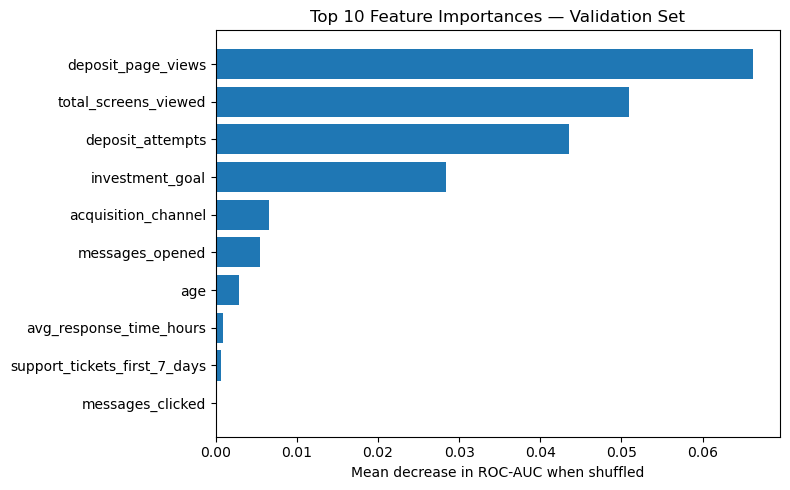

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
}).sort_values("Importance", ascending=False)

display(feature_importance.head(10).round(4))

top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Mean decrease in ROC-AUC when shuffled")
plt.title("Top 10 Feature Importances — Validation Set")
plt.tight_layout()
plt.show()

**Interpretation**

Deposit page views, total screens viewed and deposit attempts were the three most important features in the validation analysis. Investment goal was the next most important. This suggests that early platform engagement and deposit-related behaviour provide useful signals for predicting first-deposit activation. Feature importance indicates predictive contribution, not causation, and should be interpreted in light of the synthetic dataset and provisional negative labels.

## 4. Model Validation

The selected Gradient Boosting pipeline is evaluated on the validation subset of 104 customers, which was not used to train the model. This assesses performance on unseen data.

The validation set is also used to examine how different classification thresholds affect precision and recall and to select a provisional operating threshold. The test set remains separate from model training, hyperparameter selection and threshold selection.

The target is first-deposit activation between Days 8 and 30. A false negative is an activating customer the model predicts will not activate; a false positive is a non-activating customer the model predicts will activate. These errors have different practical implications, so validation considers precision, recall, F1-score and ROC-AUC alongside accuracy.

The dataset contains provisional negative labels, so the results should be interpreted with this limitation in mind.

In [9]:
# Metrics, curves and plots used throughout the validation and test sections
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)

**4.1 Validation-Set Performance**

Predicted probabilities are generated for the validation customers using the fitted pipeline, which applies the same imputation and encoding learned from the training data. The default 0.5 threshold is used first, before the threshold itself is examined.

In [10]:
# Predicted probabilities and default (0.5) class predictions on the validation set
val_proba = best_model.predict_proba(X_val)[:, 1]
val_pred = best_model.predict(X_val)

validation_metrics = {
    "accuracy": accuracy_score(y_val, val_pred),
    "precision": precision_score(y_val, val_pred),
    "recall": recall_score(y_val, val_pred),
    "f1": f1_score(y_val, val_pred),
    "roc_auc": roc_auc_score(y_val, val_proba),
    "pr_auc": average_precision_score(y_val, val_proba),
}

print("Validation-set performance (threshold = 0.50):")
for name, value in validation_metrics.items():
    print(f"  {name:10s}: {value:.4f}")

Validation-set performance (threshold = 0.50):
  accuracy  : 0.6058
  precision : 0.6486
  recall    : 0.7619
  f1        : 0.7007
  roc_auc   : 0.6671
  pr_auc    : 0.7731


At the default threshold, the model correctly separates activated from non-activated customers noticeably more often than a coin flip would, with a validation ROC-AUC of 0.67. This is close to the cross-validation ROC-AUC obtained during training (0.65), which is a reasonable first sign that the model is not simply overfitting the training folds.

At this threshold the model leans toward recall over precision for the activated class (recall 0.76 vs. precision 0.65): it catches a solid majority of customers who go on to activate, at the cost of also flagging a fair number who do not. Given the still-modest number of labelled customers available (520 in total), these figures should be read as indicative rather than precise.

**4.2 Confusion Matrix**

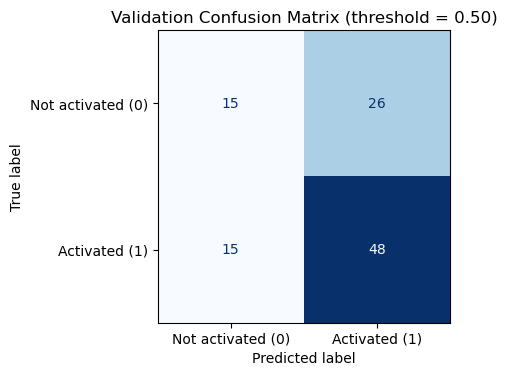

                   precision    recall  f1-score   support

Not activated (0)       0.50      0.37      0.42        41
    Activated (1)       0.65      0.76      0.70        63

         accuracy                           0.61       104
        macro avg       0.57      0.56      0.56       104
     weighted avg       0.59      0.61      0.59       104



In [11]:
# Confusion matrix on the validation set at the default threshold
val_cm = confusion_matrix(y_val, val_pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(
    val_cm, display_labels=["Not activated (0)", "Activated (1)"]
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Validation Confusion Matrix (threshold = 0.50)")
plt.tight_layout()
plt.show()

print(classification_report(
    y_val, val_pred, target_names=["Not activated (0)", "Activated (1)"]
))

Reading the matrix as true negatives, false positives, false negatives and true positives: the model correctly identifies a minority of customers who did not activate (around 15 of 41) while correctly identifying most of the customers who did (around 48 of 63). The false positives, non-activating customers wrongly flagged, are the larger error group here, which matters because an activation campaign built on this model would spend some effort on customers who were never going to need the nudge. The false negatives are fewer, but still represent activating customers the model missed.

**4.3 ROC Curve**

The ROC curve shows how the true-positive rate and false-positive rate trade off as the classification threshold is varied, independent of any single threshold choice.

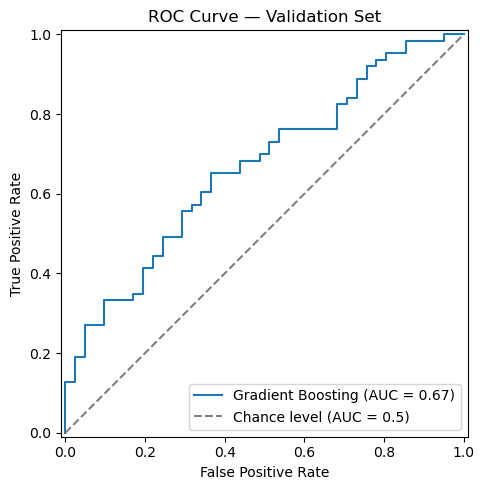

In [12]:
# ROC curve on the validation set
fig, ax = plt.subplots(figsize=(5, 5))

RocCurveDisplay.from_predictions(
    y_val,
    val_proba,
    name="Gradient Boosting",
    ax=ax,
    plot_chance_level=True,
    chance_level_kw={"color": "grey", "linestyle": "--"}
)

ax.set_title("ROC Curve — Validation Set")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
plt.tight_layout()
plt.show()

The curve sits above the diagonal chance line across its full range, confirming the model carries genuine, if modest, discriminatory ability on data it was not trained on.

**4.4 Precision–Recall Curve**

Because the two classes are not far from balanced in this labelled sample (around 60% activated), the ROC curve and the precision–recall curve tell a similar story here. The precision–recall curve is included because it is the more direct way to see the specific precision/recall trade-off relevant to targeting an activation intervention.

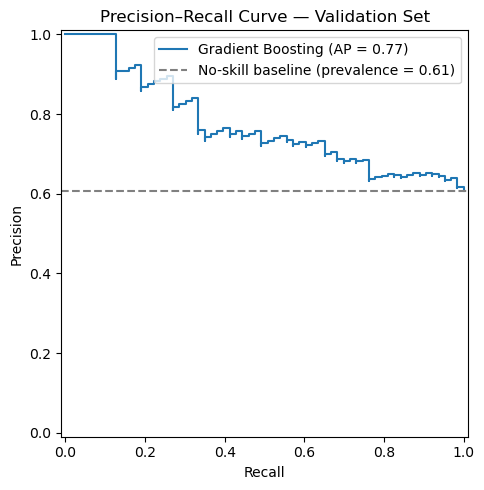

In [13]:
# Precision-recall curve on the validation set
from sklearn.metrics import PrecisionRecallDisplay

val_prevalence = y_val.mean()

fig, ax = plt.subplots(figsize=(5, 5))

PrecisionRecallDisplay.from_predictions(
    y_val,
    val_proba,
    name="Gradient Boosting",
    ax=ax
)

ax.axhline(
    val_prevalence,
    linestyle="--",
    color="grey",
    label=f"No-skill baseline (prevalence = {val_prevalence:.2f})"
)

ax.set_title("Precision–Recall Curve — Validation Set")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

The curve stays above the no-skill baseline (the validation set's activation rate) for most of its length, which means the model's ranking of customers by predicted activation probability is informative — prioritising customers by this score would concentrate activations more effectively than contacting customers at random.

**4.5 Threshold Analysis**

The 0.50 threshold used above is simply the default; nothing about this problem requires it. The cell below recomputes precision, recall and F1-score for the activated class across a range of thresholds, to show the trade-off available and to select an operating threshold using the validation set only, before the test set is touched.

In [14]:
# Precision, recall and F1 for the activated class across a range of thresholds,
# computed on the validation set only
thresholds_to_check = np.arange(0.10, 0.95, 0.05)

threshold_rows = []
for t in thresholds_to_check:
    pred_t = (val_proba >= t).astype(int)
    threshold_rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_val, pred_t, zero_division=0),
        "recall": recall_score(y_val, pred_t, zero_division=0),
        "f1": f1_score(y_val, pred_t, zero_division=0),
    })

threshold_table = pd.DataFrame(threshold_rows)
threshold_table

,threshold,precision,recall,f1
0,0.10,0.605769,1.000000,0.754491
1,0.15,0.605769,1.000000,0.754491
2,0.20,0.605769,1.000000,0.754491
3,0.25,0.611650,1.000000,0.759036
4,0.30,0.611650,1.000000,0.759036
5,0.35,0.626263,0.984127,0.765432
6,0.40,0.638298,0.952381,0.764331
7,0.45,0.642857,0.857143,0.734694
8,0.50,0.648649,0.761905,0.700730
9,0.55,0.704918,0.682540,0.693548


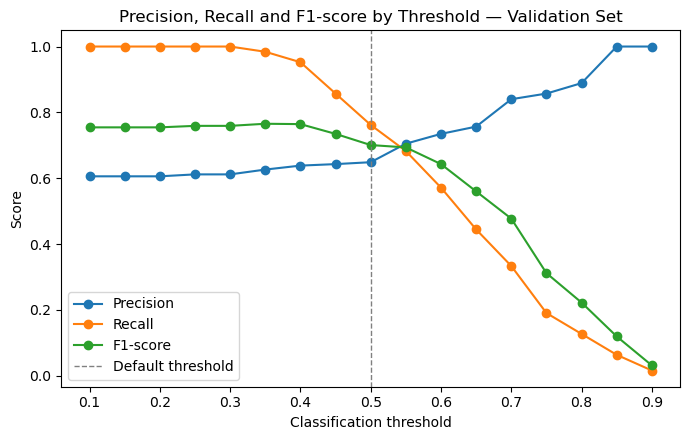

Threshold that maximises F1 on the validation set: 0.35
 threshold  precision   recall       f1
      0.35   0.626263 0.984127 0.765432


In [15]:
# Plot the trade-off across thresholds
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(threshold_table["threshold"], threshold_table["precision"], marker="o", label="Precision")
ax.plot(threshold_table["threshold"], threshold_table["recall"], marker="o", label="Recall")
ax.plot(threshold_table["threshold"], threshold_table["f1"], marker="o", label="F1-score")
ax.axvline(0.50, linestyle="--", color="grey", linewidth=1, label="Default threshold")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.set_title("Precision, Recall and F1-score by Threshold — Validation Set")
ax.legend()
plt.tight_layout()
plt.show()

# Threshold that maximises F1 on the validation set
chosen_threshold = threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"]
print(f"Threshold that maximises F1 on the validation set: {chosen_threshold:.2f}")
print(threshold_table[threshold_table["threshold"] == chosen_threshold].to_string(index=False))

**Threshold Analysis Interpretation**

Lowering the classification threshold increases recall at the expense of precision, while raising it generally increases precision and reduces recall. The threshold of 0.35 gives the highest F1-score among the thresholds tested on the validation set.

This threshold is a provisional choice based on validation performance. In practice, the appropriate threshold would depend on the cost of unnecessary customer outreach, the risk of missing potential activations, and the activation team's capacity. These operational costs are not available in the current dataset.